262220016 - sdsawant_m26@el.vjti.ac.in

# IALM — Experiment No. 1
## Data Exploration and Cleaning

**Objective:** To explore and clean a real-world dataset using Python,
analyze its statistical properties and relationships, apply suitable
data transformations, and communicate the findings through
visualizations.

**Dataset:** Bike Sharing Daily Dataset (`day.csv`)

**Tools Used:** Python, Pandas, NumPy, Matplotlib, Seaborn, and Jupyter Notebook.

## 1. Problem Understanding and Approach

Data exploration helps understand a dataset's structure, distributions,
and relationships, while data cleaning helps identify potential
quality issues before analysis.

This experiment follows a systematic workflow:

1. Load the dataset and examine its structure.
2. Assess data quality and validate records.
3. Investigate distributions, outliers, and relationships.
4. Apply suitable data transformations.
5. Visualize and interpret the findings.

## 1. Imports and setup

### Before running
Importing the libraries used for data handling, numerical operations, and visualization. Setting a consistent plotting style so charts are easier to compare.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

Loading the **Bike Sharing daily dataset** `day.csv` into a Pandas DataFrame. The CSV is kept in the same folder as this notebook. The fallback path supports the google colab. environment or any mounted data in enviornment.

In [2]:
# Load the dataset
from pathlib import Path

dataset_path = Path("day.csv")
if not dataset_path.exists():
    dataset_path = Path("/mnt/data/day.csv")

df = pd.read_csv(dataset_path)

print("Dataset loaded successfully.")
print("File:", dataset_path)
print("Rows and columns:", df.shape)
display(df.head())

Dataset loaded successfully.
File: day.csv
Rows and columns: (731, 16)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


## 2. Initial Data Understanding

Examining the dataset's dimensions, column names, data types, and descriptive statistics before making any changes. This establishes a baseline for the cleaning and analysis steps.

In [3]:
# Structure, dimensions, and data types
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

print("\\nColumn names:")
print(df.columns.tolist())

print("\\nData types and non-null counts:")
df.info()

Number of rows: 731
Number of columns: 16
\nColumn names:
['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']
\nData types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    in

In [4]:
# Descriptive statistics for numerical columns
print("Descriptive statistics of the dataset:")
display(df.describe().T.round(2))

Descriptive statistics of the dataset:


,count,mean,std,min,25%,50%,75%,max
instant,731.0,366.00,211.17,1.00,183.50,366.00,548.50,731.00
season,731.0,2.50,1.11,1.00,2.00,3.00,3.00,4.00
yr,731.0,0.50,0.50,0.00,0.00,1.00,1.00,1.00
mnth,731.0,6.52,3.45,1.00,4.00,7.00,10.00,12.00
holiday,731.0,0.03,0.17,0.00,0.00,0.00,0.00,1.00
weekday,731.0,3.00,2.00,0.00,1.00,3.00,5.00,6.00
workingday,731.0,0.68,0.47,0.00,0.00,1.00,1.00,1.00
weathersit,731.0,1.40,0.54,1.00,1.00,1.00,2.00,3.00
temp,731.0,0.50,0.18,0.06,0.34,0.50,0.66,0.86
atemp,731.0,0.47,0.16,0.08,0.34,0.49,0.61,0.84


## 3. Data Quality Checks and Cleaning

In [5]:
# Check missing values and duplicate records
missing_summary = pd.DataFrame({
    "Missing values": df.isna().sum(),
    "Missing (%)": (df.isna().mean() * 100).round(2)
})

display(missing_summary)
print("Completely duplicated rows:", df.duplicated().sum())
print("Unique record IDs:", df["instant"].nunique(), "out of", len(df), "rows")

,Missing values,Missing (%)
instant,0,0.0
dteday,0,0.0
season,0,0.0
yr,0,0.0
mnth,0,0.0
holiday,0,0.0
weekday,0,0.0
workingday,0,0.0
weathersit,0,0.0
temp,0,0.0


Completely duplicated rows: 0
Unique record IDs: 731 out of 731 rows


Before analysing patterns, I checked the dataset for missing values, duplicate records, and consistency between related columns. A cleaning operation should only be applied when a problem is actually found; valid observations are not removed merely to make the dataset look cleaner.

### Checking the rental-count relationship

In [6]:
# Verify the relationship between casual, registered, and total rentals
rental_mismatch = df["cnt"] != (df["casual"] + df["registered"])
print("Rows where cnt != casual + registered:", int(rental_mismatch.sum()))

if rental_mismatch.any():
    display(df.loc[rental_mismatch, ["dteday", "casual", "registered", "cnt"]].head(10))
else:
    print("All rows satisfy cnt = casual + registered.")

# Apply cleaning only if duplicate rows are present.
# This dataset is expected to be inspected first; do not remove rows automatically.
if df.duplicated().any():
    print("Duplicate rows were detected. Review them before deciding whether to remove them.")
else:
    print("No duplicate rows need to be removed.")

Rows where cnt != casual + registered: 0
All rows satisfy cnt = casual + registered.
No duplicate rows need to be removed.


The dataset defines total rentals (`cnt`) as the sum of casual and registered rentals. I checked this relationship before making any corrections. If mismatches exist, they are displayed for inspection rather than silently overwritten.

## 4. Date and Categorical-Value Validation

Converting `dteday` to Pandas datetime format and checked the date range. Also checking coded categorical columns against their expected values. Invalid entries are reported so that they can be investigated instead of being silently replaced.

In [7]:
# Convert dates and identify values that could not be parsed
df["dteday"] = pd.to_datetime(df["dteday"], errors="coerce")
print("Invalid dates:", int(df["dteday"].isna().sum()))
print("Date range:", df["dteday"].min(), "to", df["dteday"].max())

expected_values = {
    "season": [1, 2, 3, 4],
    "yr": [0, 1],
    "mnth": list(range(1, 13)),
    "weekday": list(range(0, 7)),
    "holiday": [0, 1],
    "workingday": [0, 1],
    "weathersit": [1, 2, 3, 4]
}

validation_rows = []
for column, valid_values in expected_values.items():
    unexpected = df.loc[~df[column].isin(valid_values), column].dropna().unique().tolist()
    validation_rows.append({
        "Column": column,
        "Distinct values": df[column].nunique(),
        "Unexpected values": unexpected if unexpected else "None"
    })
display(pd.DataFrame(validation_rows))

Invalid dates: 0
Date range: 2011-01-01 00:00:00 to 2012-12-31 00:00:00


,Column,Distinct values,Unexpected values
0,season,4,None
1,yr,2,None
2,mnth,12,None
3,weekday,7,None
4,holiday,2,None
5,workingday,2,None
6,weathersit,3,None


## 5. Numerical Range and Outlier Analysis
Inspecting the ranges of the main weather and rental-count variables, then using box plots and the interquartile range (IQR) rule to flag potential outliers. The IQR rule identifies unusual values statistically; it does **not** prove that a value is an error. Since high rental counts may reflect genuine demand, flagged observations are retained unless there is evidence of incorrect data.

,min,median,max
Variable,,,
temp,0.059,0.498,0.862
atemp,0.079,0.487,0.841
hum,0.000,0.627,0.972
windspeed,0.022,0.181,0.507
casual,2.000,713.000,3410.000
registered,20.000,3662.000,6946.000
cnt,22.000,4548.000,8714.000


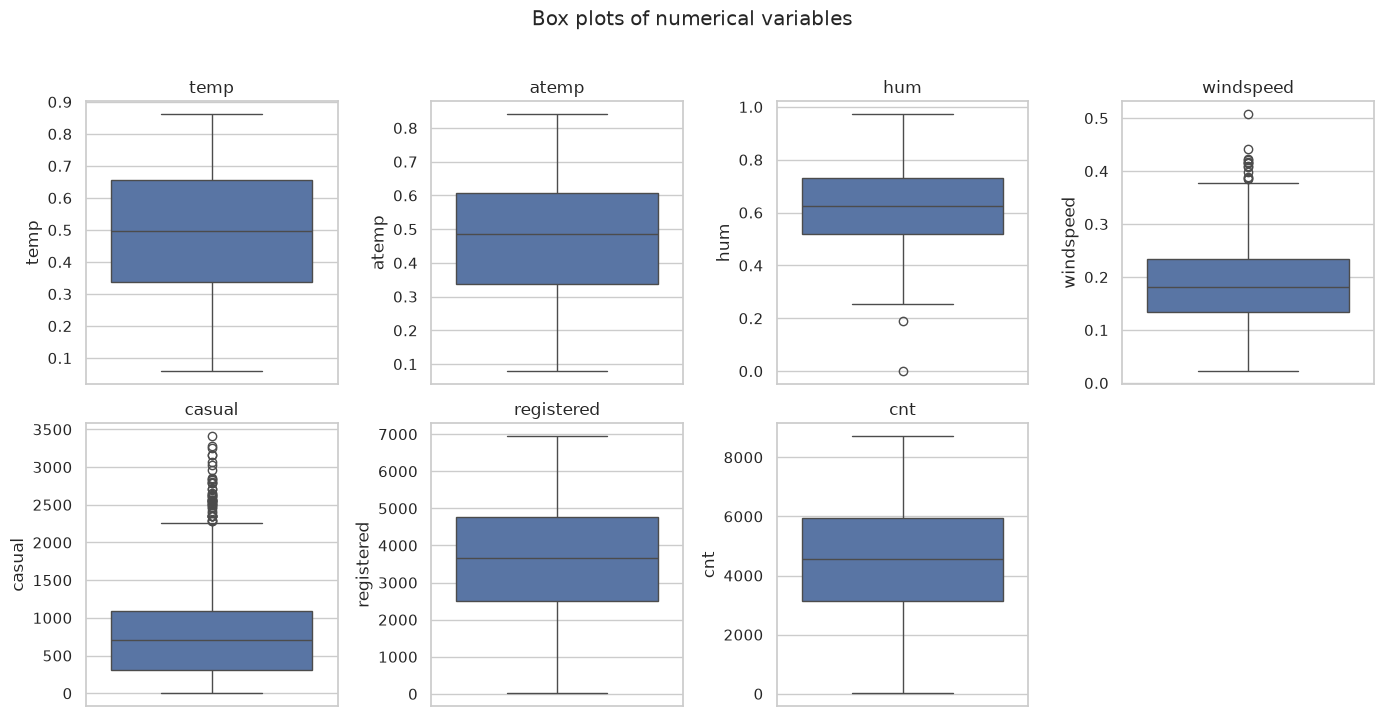

In [8]:
numeric_columns = ["temp", "atemp", "hum", "windspeed", "casual", "registered", "cnt"]
display(df[numeric_columns].agg(["min", "median", "max"]).T.round(3).rename_axis("Variable"))

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, column in zip(axes.flat, numeric_columns):
    sns.boxplot(y=df[column], ax=ax)
    ax.set_title(column)
for ax in axes.flat[len(numeric_columns):]:
    ax.set_visible(False)
fig.suptitle("Box plots of numerical variables", y=1.02)
plt.tight_layout()
plt.show()

For each rental-count variable, the lower and upper screening limits are `Q1 − 1.5 × IQR` and `Q3 + 1.5 × IQR`. The table reports how many records fall outside those limits.

In [9]:
count_columns = ["casual", "registered", "cnt"]
outlier_rows = []
for column in count_columns:
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (df[column] < lower) | (df[column] > upper)
    outlier_rows.append({
        "Variable": column, "Q1": q1, "Q3": q3, "IQR": iqr,
        "Lower limit": lower, "Upper limit": upper,
        "Potential outliers": int(mask.sum())
    })
display(pd.DataFrame(outlier_rows).round(2))

,Variable,Q1,Q3,IQR,Lower limit,Upper limit,Potential outliers
0,casual,315.5,1096.0,780.5,-855.25,2266.75,44
1,registered,2497.0,4776.5,2279.5,-922.25,8195.75,0
2,cnt,3152.0,5956.0,2804.0,-1054.00,10162.00,0


Potential outliers are retained because the statistical rule alone does not establish data errors.

## 6. Univariate Analysis: Rental-Count Distributions

Univariate analysis examines one variable at a time. These histograms compare casual, registered, and total daily rentals and help reveal spread, concentration, and skewness. The plots are descriptive; the actual distribution shape should be judged from the displayed results.

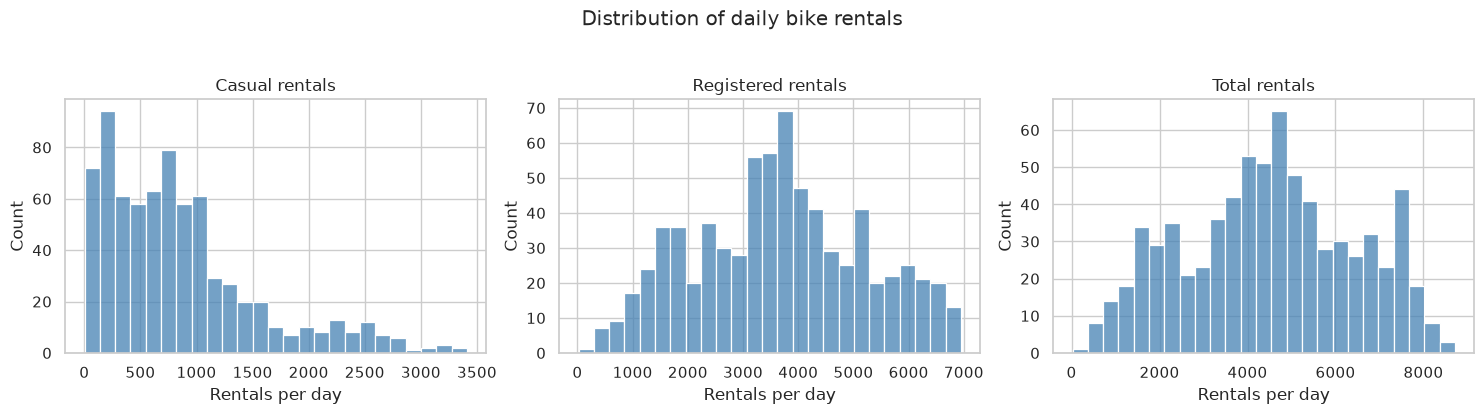

Skewness of rental-count variables (positive values indicate right-skew):


,Skewness
casual,1.27
registered,0.04
cnt,-0.05


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column, title in zip(
    axes,
    ["casual", "registered", "cnt"],
    ["Casual rentals", "Registered rentals", "Total rentals"]
):
    sns.histplot(data=df, x=column, bins=25, color="steelblue", ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Rentals per day")
fig.suptitle("Distribution of daily bike rentals", y=1.03)
plt.tight_layout()
plt.show()

print("Skewness of rental-count variables (positive values indicate right-skew):")
display(df[["casual", "registered", "cnt"]].skew().to_frame("Skewness").round(2))

## 7. Bivariate Analysis: Rentals by Season

Comparing the average daily total rentals across seasons. The bar chart shows the group averages, while the summary table provides the numerical values. The season labels follow the dataset's category coding.

,Average rentals,Median rentals,Days
season,,,
Spring,2604.13,2209.0,181
Summer,4992.33,4941.5,184
Fall,5644.30,5353.5,188
Winter,4728.16,4634.5,178


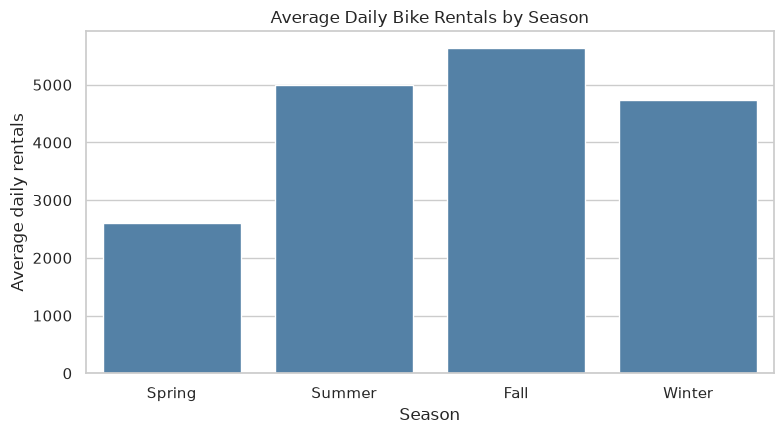

In [11]:
season_names = {1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"}
season_summary = (
    df.groupby("season")["cnt"].agg(["mean", "median", "count"])
      .rename(columns={"mean": "Average rentals", "median": "Median rentals", "count": "Days"})
)
season_summary.index = season_summary.index.map(season_names)
display(season_summary.round(2))

plt.figure(figsize=(8, 4.5))
sns.barplot(data=df.assign(season_name=df["season"].map(season_names)),
            x="season_name", y="cnt", estimator=np.mean, errorbar=None, color="steelblue")
plt.title("Average Daily Bike Rentals by Season")
plt.xlabel("Season")
plt.ylabel("Average daily rentals")
plt.tight_layout()
plt.show()

## 8. Bivariate Analysis: Rentals by Weather Situation

Comparing total rentals across the coded weather situations. The category descriptions are used as plot labels to make the result easier to interpret.

,Average rentals,Median rentals,Days
weathersit,,,
Clear / partly cloudy,4876.79,4844.0,463
Mist / cloudy,4035.86,4040.0,247
Light rain / snow,1803.29,1817.0,21


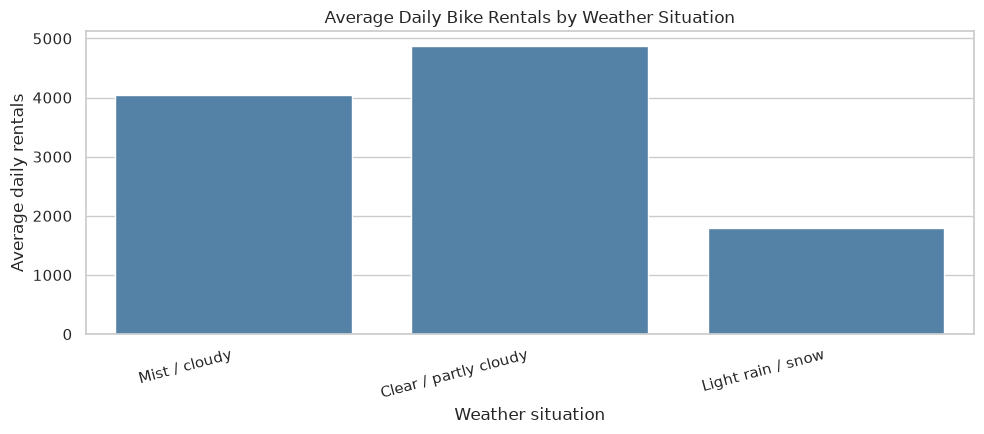

In [12]:
weather_names = {
    1: "Clear / partly cloudy",
    2: "Mist / cloudy",
    3: "Light rain / snow",
    4: "Heavy rain / snow"
}
weather_summary = (
    df.groupby("weathersit")["cnt"].agg(["mean", "median", "count"])
      .rename(columns={"mean": "Average rentals", "median": "Median rentals", "count": "Days"})
)
weather_summary.index = weather_summary.index.map(weather_names)
display(weather_summary.round(2))

plot_df = df.assign(weather_label=df["weathersit"].map(weather_names))
plt.figure(figsize=(10, 4.5))
sns.barplot(data=plot_df, x="weather_label", y="cnt", estimator=np.mean, errorbar=None, color="steelblue")
plt.title("Average Daily Bike Rentals by Weather Situation")
plt.xlabel("Weather situation")
plt.ylabel("Average daily rentals")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

Group averages can show association, but do not by themselves establish that weather caused the difference.

## 9. Correlation Analysis

Pearson correlation measures the direction and strength of a **linear** relationship between numerical variables. Values closer to +1 indicate a stronger positive linear association, values closer to −1 a stronger negative association, and values near 0 a weaker linear association. Correlation does not establish causation.

,temp,atemp,hum,windspeed,casual,registered,cnt
temp,1.00,0.99,0.13,-0.16,0.54,0.54,0.63
atemp,0.99,1.00,0.14,-0.18,0.54,0.54,0.63
hum,0.13,0.14,1.00,-0.25,-0.08,-0.09,-0.10
windspeed,-0.16,-0.18,-0.25,1.00,-0.17,-0.22,-0.23
casual,0.54,0.54,-0.08,-0.17,1.00,0.40,0.67
registered,0.54,0.54,-0.09,-0.22,0.40,1.00,0.95
cnt,0.63,0.63,-0.10,-0.23,0.67,0.95,1.00


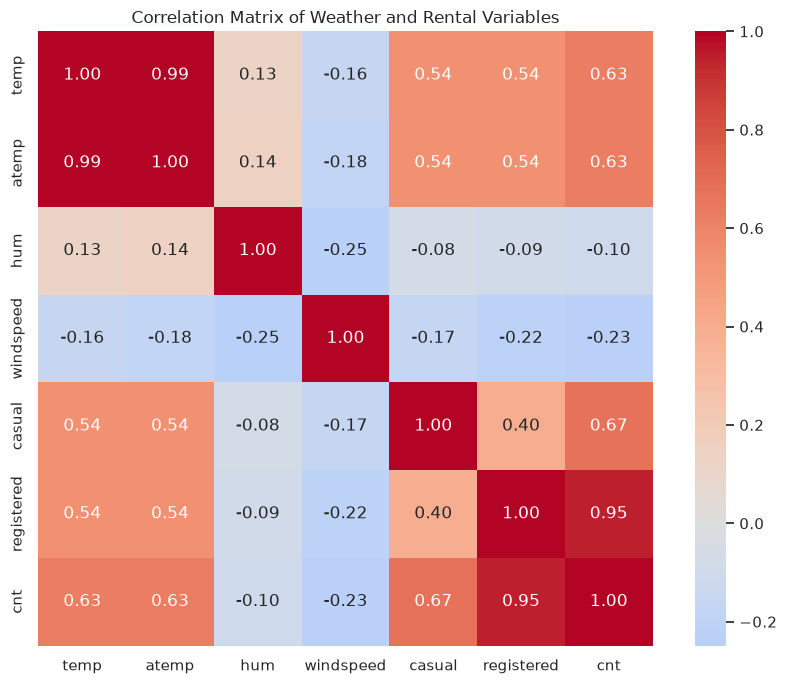

In [13]:
correlation_columns = ["temp", "atemp", "hum", "windspeed", "casual", "registered", "cnt"]
correlation_matrix = df[correlation_columns].corr(numeric_only=True)
display(correlation_matrix.round(2))

plt.figure(figsize=(9, 7))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Matrix of Weather and Rental Variables")
plt.tight_layout()
plt.show()

## 10. Bivariate Analysis: Temperature and Total Rentals

A scatter plot helps inspect the relationship between normalized temperature (`temp`) and total daily rentals (`cnt`). 

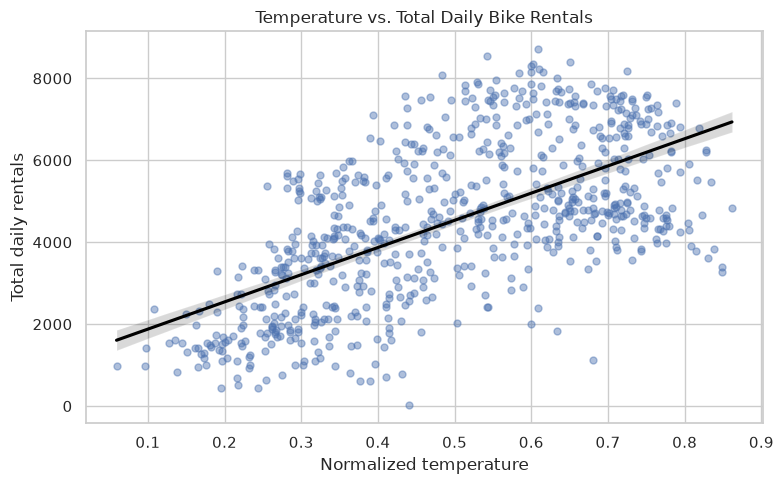

Pearson correlation (temp, cnt): 0.627


In [14]:
plt.figure(figsize=(8, 5))
sns.regplot(data=df, x="temp", y="cnt",
            scatter_kws={"alpha": 0.45, "s": 25},
            line_kws={"color": "black"})
plt.title("Temperature vs. Total Daily Bike Rentals")
plt.xlabel("Normalized temperature")
plt.ylabel("Total daily rentals")
plt.tight_layout()
plt.show()

print("Pearson correlation (temp, cnt):", round(df["temp"].corr(df["cnt"]), 3))

The fitted line summarizes the overall linear trend; individual points show day-to-day variation.

## 11. Data Transformation

### 11.1 Log transformation of rental counts

Rental counts may be right-skewed. Using `log1p(x) = log(1 + x)`, which also works when a count is zero. The transformed columns are added for comparison; the original count columns are preserved.

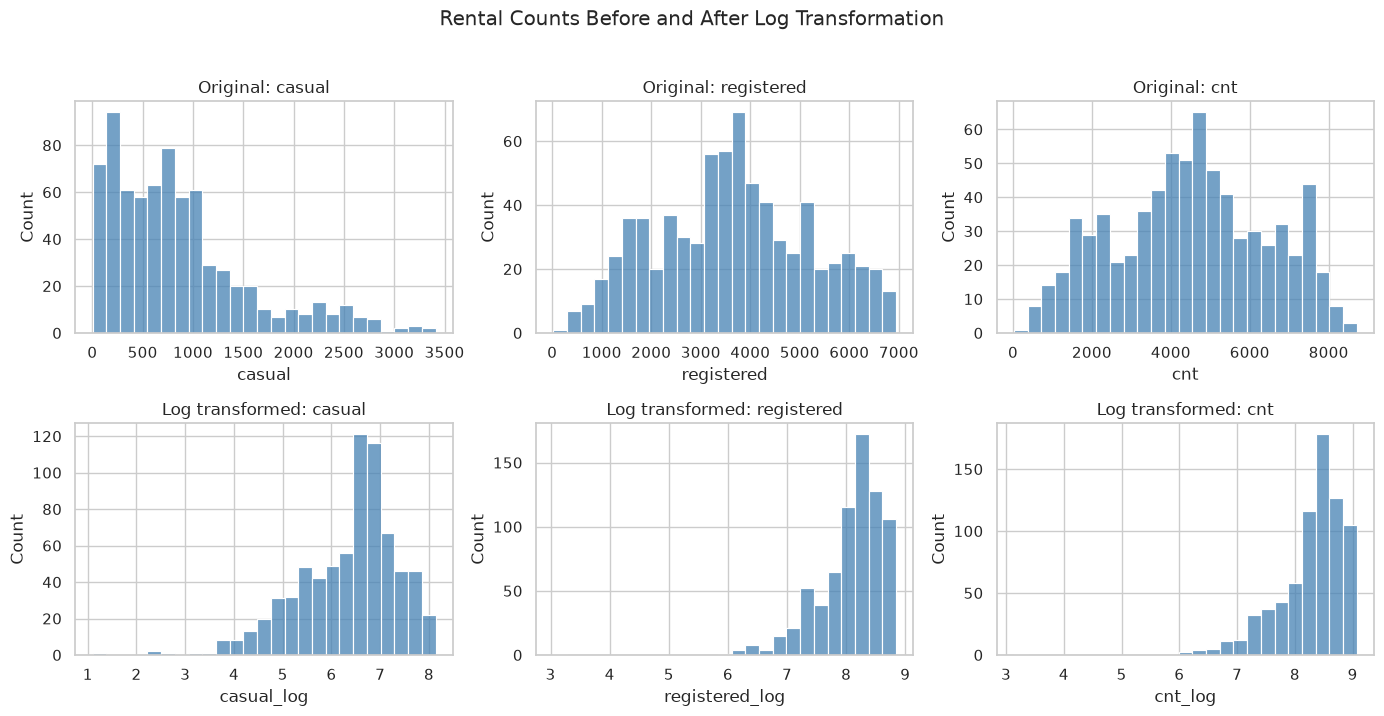

,Original skewness,Log-transformed skewness
casual,1.27,-0.92
registered,0.04,-1.89
cnt,-0.05,-1.91


In [15]:
log_columns = {"casual": "casual_log", "registered": "registered_log", "cnt": "cnt_log"}
for original, transformed in log_columns.items():
    df[transformed] = np.log1p(df[original])

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for col, ax_top, ax_bottom in zip(log_columns, axes[0], axes[1]):
    sns.histplot(df[col], bins=25, color="steelblue", ax=ax_top)
    ax_top.set_title(f"Original: {col}")
    sns.histplot(df[log_columns[col]], bins=25, color="steelblue", ax=ax_bottom)
    ax_bottom.set_title(f"Log transformed: {col}")
fig.suptitle("Rental Counts Before and After Log Transformation", y=1.02)
plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "Original skewness": df[list(log_columns)].skew(),
    "Log-transformed skewness": df[list(log_columns.values())].skew().values
}, index=list(log_columns.keys())).round(2))

A log transformation can reduce skewness but does not guarantee a normal distribution.

### 11.2 Standardization of weather variables

Standardization converts each variable to a z-score by subtracting its mean and dividing by its standard deviation. This places the selected variables on a comparable scale. Storing the standardized data in a separate DataFrame, leaving the original measurements unchanged.

In [16]:
weather_columns = ["temp", "atemp", "hum", "windspeed"]
df_standardized = df.copy()
weather_means = df[weather_columns].mean()
weather_stds = df[weather_columns].std(ddof=0)
df_standardized[[f"{col}_z" for col in weather_columns]] = (
    df[weather_columns] - weather_means
) / weather_stds

print("First five standardized observations:")
display(df_standardized[[f"{col}_z" for col in weather_columns]].head().round(3))
print("Means (approximately 0):")
display(df_standardized[[f"{col}_z" for col in weather_columns]].mean().round(3))
print("Standard deviations (approximately 1):")
display(df_standardized[[f"{col}_z" for col in weather_columns]].std(ddof=0).round(3))

First five standardized observations:


,temp_z,atemp_z,hum_z,windspeed_z
0,-0.827,-0.680,1.250,-0.388
1,-0.721,-0.741,0.479,0.750
2,-1.635,-1.750,-1.339,0.747
3,-1.615,-1.610,-0.263,-0.390
4,-1.467,-1.505,-1.341,-0.046


Means (approximately 0):


temp_z        -0.0
atemp_z        0.0
hum_z         -0.0
windspeed_z   -0.0
dtype: float64

Standard deviations (approximately 1):


temp_z         1.0
atemp_z        1.0
hum_z          1.0
windspeed_z    1.0
dtype: float64

## 12. Monthly Rental Trends

Grouping the daily records by month and calculated the average number of rentals.

,Average daily rentals
mnth,
Jan,2176.34
Feb,2655.30
Mar,3692.26
Apr,4484.90
May,5349.77
Jun,5772.37
Jul,5563.68
Aug,5664.42
Sep,5766.52


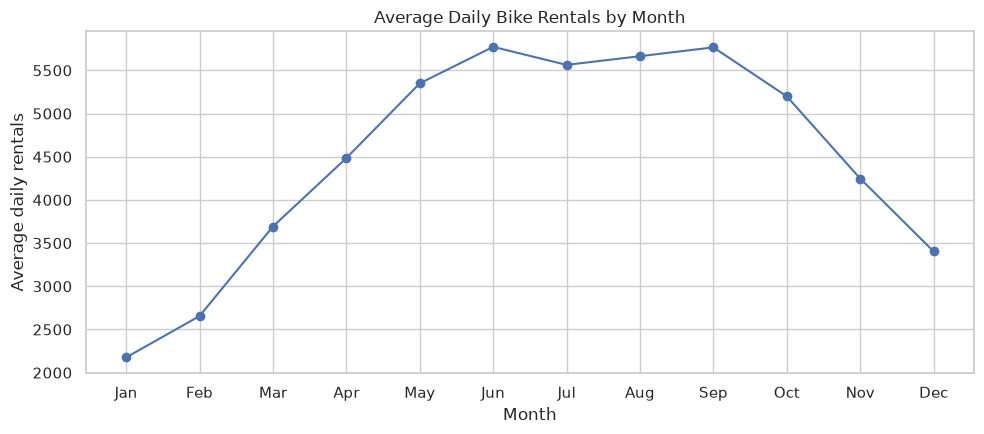

In [17]:
month_names = {1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "May", 6: "Jun",
               7: "Jul", 8: "Aug", 9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec"}
monthly_rentals = df.groupby("mnth")["cnt"].mean().reindex(range(1, 13))
monthly_summary = monthly_rentals.rename(index=month_names).to_frame("Average daily rentals")
display(monthly_summary.round(2))

plt.figure(figsize=(10, 4.5))
plt.plot([month_names[m] for m in monthly_rentals.index], monthly_rentals.values, marker="o")
plt.title("Average Daily Bike Rentals by Month")
plt.xlabel("Month")
plt.ylabel("Average daily rentals")
plt.tight_layout()
plt.show()

Because the dataset spans two years, each monthly average combines observations from both years and gives a broad view of the annual pattern.

## 13. Final Data Quality Check

This final check confirms the quality of the original dataset after validation. Analysis-only columns (such as log-transformed values and display labels) are not treated as corrections to the source measurements.

In [18]:
original_columns = [
    "instant", "dteday", "season", "yr", "mnth", "holiday", "weekday",
    "workingday", "weathersit", "temp", "atemp", "hum", "windspeed",
    "casual", "registered", "cnt"
]
original_columns = [col for col in original_columns if col in df.columns]

quality_report = pd.Series({
    "Rows": len(df),
    "Original dataset columns": len(original_columns),
    "Missing values in original columns": int(df[original_columns].isna().sum().sum()),
    "Duplicate rows": int(df[original_columns].duplicated().sum()),
    "Invalid dates": int(df["dteday"].isna().sum()),
    "Rental-total mismatches": int((df["cnt"] != df["casual"] + df["registered"]).sum())
}, name="Result")
display(quality_report.to_frame())
print("Date range:", df["dteday"].min().date(), "to", df["dteday"].max().date())

,Result
Rows,731
Original dataset columns,16
Missing values in original columns,0
Duplicate rows,0
Invalid dates,0
Rental-total mismatches,0


Date range: 2011-01-01 to 2012-12-31


## 14. Key Findings and Conclusion

The statements below are generated from the dataset so the conclusion reflects the observed results rather than assumed patterns.

In [19]:
# 1. Dataset overview
total_records = len(df)
total_columns = len(original_columns)
date_start = df["dteday"].min()
date_end = df["dteday"].max()

# 2. Data quality
missing_values = int(df[original_columns].isna().sum().sum())
duplicate_rows = int(df[original_columns].duplicated().sum())
invalid_dates = int(df["dteday"].isna().sum())

rental_mismatches = int(
    (df["cnt"] != df["casual"] + df["registered"]).sum()
)

invalid_categories = {
    "season": [1, 2, 3, 4],
    "yr": [0, 1],
    "mnth": list(range(1, 13)),
    "weekday": list(range(7)),
    "holiday": [0, 1],
    "workingday": [0, 1],
    "weathersit": [1, 2, 3, 4]
}

invalid_category_count = sum(
    int((~df[column].isin(valid_values)).sum())
    for column, valid_values in invalid_categories.items()
)

# 3. Rental statistics
average_rentals = df["cnt"].mean()
median_rentals = df["cnt"].median()
minimum_rentals = df["cnt"].min()
maximum_rentals = df["cnt"].max()

registered_share = (
    df["registered"].sum() / df["cnt"].sum() * 100
    if df["cnt"].sum() != 0 else float("nan")
)

casual_share = (
    df["casual"].sum() / df["cnt"].sum() * 100
    if df["cnt"].sum() != 0 else float("nan")
)

# 4. Seasonal and weather analysis
season_labels = {
    1: "Spring",
    2: "Summer",
    3: "Fall",
    4: "Winter"
}

weather_labels = {
    1: "Clear / partly cloudy",
    2: "Mist / cloudy",
    3: "Light rain / snow",
    4: "Heavy rain / snow"
}

season_means = df.groupby("season")["cnt"].mean()
weather_means = df.groupby("weathersit")["cnt"].mean()

best_season = season_labels[season_means.idxmax()]
best_season_mean = season_means.max()

lowest_season = season_labels[season_means.idxmin()]
lowest_season_mean = season_means.min()

best_weather = weather_labels[weather_means.idxmax()]
best_weather_mean = weather_means.max()

# 5. Monthly trend analysis
monthly_means = df.groupby("mnth")["cnt"].mean()

month_labels = {
    1: "January", 2: "February", 3: "March",
    4: "April", 5: "May", 6: "June",
    7: "July", 8: "August", 9: "September",
    10: "October", 11: "November", 12: "December"
}

highest_month = month_labels[monthly_means.idxmax()]
highest_month_mean = monthly_means.max()

lowest_month = month_labels[monthly_means.idxmin()]
lowest_month_mean = monthly_means.min()

# 6. Correlation analysis
temperature_correlation = df["temp"].corr(df["cnt"])
humidity_correlation = df["hum"].corr(df["cnt"])
windspeed_correlation = df["windspeed"].corr(df["cnt"])

rental_correlations = (
    df[["temp", "atemp", "hum", "windspeed"]]
    .corrwith(df["cnt"])
    .dropna()
)

strongest_variable = rental_correlations.abs().idxmax()
strongest_correlation = rental_correlations[strongest_variable]

# 7. Distribution and transformation analysis
rental_columns = ["casual", "registered", "cnt"]

original_skewness = df[rental_columns].skew()
transformed_skewness = df[
    ["casual_log", "registered_log", "cnt_log"]
].skew()

total_rental_skew_before = original_skewness["cnt"]
total_rental_skew_after = transformed_skewness["cnt_log"]

if abs(total_rental_skew_after) < abs(total_rental_skew_before):
    log_interpretation = (
        "The log transformation reduced the absolute skewness "
        "of total rental counts."
    )
elif abs(total_rental_skew_after) > abs(total_rental_skew_before):
    log_interpretation = (
        "The log transformation increased the absolute skewness "
        "of total rental counts."
    )
else:
    log_interpretation = (
        "The absolute skewness of total rental counts remained unchanged."
    )

# 8. Outlier summary
outlier_summary = []

for column in rental_columns:
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1

    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    count = int(
        ((df[column] < lower_limit) |
         (df[column] > upper_limit)).sum()
    )

    outlier_summary.append((column, count))

# 9. Standardization verification
weather_columns = ["temp", "atemp", "hum", "windspeed"]

standardized_columns = [f"{column}_z" for column in weather_columns]

if all(column in df_standardized.columns
       for column in standardized_columns):

    standardized_means = df_standardized[
        standardized_columns
    ].mean()

    standardized_stds = df_standardized[
        standardized_columns
    ].std(ddof=0)

    standardization_valid = (
        standardized_means.abs().max() < 1e-6
        and (standardized_stds - 1).abs().max() < 1e-6
    )
else:
    standardization_valid = False

# ============================================================
# DISPLAY CONCLUSION
# ============================================================

# Dataset overview
print("\n1. DATASET OVERVIEW")
print("-" * 68)

print(f"Observations              : {total_records:,} daily records")
print(f"Original variables        : {total_columns}")
print(f"Observation period        : {date_start:%d %b %Y} "
      f"to {date_end:%d %b %Y}")

print(
    "The dataset contains daily bike rental counts alongside "
    "seasonal, calendar, and weather-related information."
)

# Data quality
print("\n2. DATA QUALITY AND CLEANING")
print("-" * 68)

print(f"Missing values            : {missing_values}")
print(f"Duplicate records         : {duplicate_rows}")
print(f"Invalid dates             : {invalid_dates}")
print(f"Invalid categorical values: {invalid_category_count}")
print(f"Rental-total mismatches   : {rental_mismatches}")

if all(value == 0 for value in [
    missing_values,
    duplicate_rows,
    invalid_dates,
    invalid_category_count,
    rental_mismatches
]):
    print(
        "Assessment                : The checks found no missing values, "
        "duplicates, invalid dates, invalid category codes, or "
        "inconsistent rental totals."
    )
else:
    print(
        "Assessment                : One or more data quality issues "
        "remain and should be reviewed."
    )

print(
    "Potential outliers were investigated using the IQR method. "
    "They were retained because statistical extremeness alone "
    "does not establish that a record is erroneous."
)

print("\nPotential outliers identified:")
for column, count in outlier_summary:
    print(f"  {column:<24}: {count}")

# Rental statistics
print("\n3. RENTAL STATISTICS")
print("-" * 68)

print(f"Mean daily rentals        : {average_rentals:,.2f}")
print(f"Median daily rentals      : {median_rentals:,.2f}")
print(f"Minimum daily rentals     : {minimum_rentals:,}")
print(f"Maximum daily rentals     : {maximum_rentals:,}")
print(f"Registered rental share   : {registered_share:.2f}%")
print(f"Casual rental share       : {casual_share:.2f}%")

if average_rentals > median_rentals:
    print(
        "Distribution insight      : The mean exceeds the median, "
        "suggesting a right-skewed distribution."
    )
elif average_rentals < median_rentals:
    print(
        "Distribution insight      : The mean is below the median, "
        "suggesting a left-skewed distribution."
    )
else:
    print(
        "Distribution insight      : The mean and median are equal."
    )

# Seasonal and weather findings
print("\n4. SEASONAL AND WEATHER PATTERNS")
print("-" * 68)

print(
    f"Highest-rental season     : {best_season} "
    f"({best_season_mean:,.2f} rentals/day)"
)

print(
    f"Lowest-rental season      : {lowest_season} "
    f"({lowest_season_mean:,.2f} rentals/day)"
)

print(
    f"Highest-rental weather    : {best_weather} "
    f"({best_weather_mean:,.2f} rentals/day)"
)

print(
    "Interpretation            : Seasonal and weather categories "
    "show differences in average rental demand. These are separate "
    "group comparisons and should not be interpreted as independent "
    "causal effects."
)

# Monthly findings
print("\n5. MONTHLY RENTAL TRENDS")
print("-" * 68)

print(
    f"Highest monthly average   : {highest_month} "
    f"({highest_month_mean:,.2f} rentals/day)"
)

print(
    f"Lowest monthly average    : {lowest_month} "
    f"({lowest_month_mean:,.2f} rentals/day)"
)

print(
    "Interpretation            : Monthly averages reveal how rental "
    "activity changes throughout the year. Since the dataset spans "
    "two years, each monthly average combines observations from "
    "both years."
)

# Correlation findings
print("\n6. CORRELATION ANALYSIS")
print("-" * 68)

print(f"Temperature vs rentals    : r = {temperature_correlation:.3f}")
print(f"Humidity vs rentals       : r = {humidity_correlation:.3f}")
print(f"Wind speed vs rentals     : r = {windspeed_correlation:.3f}")

print(
    f"Strongest absolute correlation among the selected weather "
    f"variables: {strongest_variable} "
    f"(r = {strongest_correlation:.3f})."
)

if temperature_correlation > 0:
    print(
        "Temperature insight       : Higher temperatures tend to "
        "accompany higher rental counts."
    )
elif temperature_correlation < 0:
    print(
        "Temperature insight       : Higher temperatures tend to "
        "accompany lower rental counts."
    )
else:
    print(
        "Temperature insight       : No linear temperature-rental "
        "association was detected."
    )

print(
    "Correlation measures linear association, not causation. "
    "Seasonal averages, weather-category averages, and correlations "
    "describe different aspects of rental demand."
)

# Transformations
print("\n7. DATA TRANSFORMATION")
print("-" * 68)

print(
    f"Total-rental skewness      : {total_rental_skew_before:.3f} "
    f"before and {total_rental_skew_after:.3f} after log transformation."
)

print(f"Log transformation         : {log_interpretation}")

print(
    "Standardization            : "
    + (
        "Verified; standardized weather variables have means "
        "approximately 0 and standard deviations approximately 1."
        if standardization_valid
        else "The standardized variables require verification."
    )
)

print(
    "The original measurements were retained, allowing transformed "
    "values to be compared with the original distributions."
)

# Overall conclusion
print("\n8. OVERALL CONCLUSION")
print("-" * 68)

print(
    f"The analysis of {total_records:,} daily observations examined "
    "data quality, rental distributions, seasonal and weather-related "
    "differences, monthly trends, correlations, and transformations."
)

print(
    f"The highest seasonal average occurred in {best_season}, while "
    f"{best_weather.lower()} conditions had the highest average "
    "among the weather categories."
)

print(
    f"Temperature had a Pearson correlation of "
    f"{temperature_correlation:.3f} with total daily rentals, "
    "indicating the direction and strength of their linear association."
)

print(
    "Together, the analyses demonstrate how exploratory data analysis "
    "can identify data quality issues, summarize distributions, reveal "
    "patterns, and investigate relationships. These findings describe "
    "the observed dataset and do not establish causal relationships."
)


1. DATASET OVERVIEW
--------------------------------------------------------------------
Observations              : 731 daily records
Original variables        : 16
Observation period        : 01 Jan 2011 to 31 Dec 2012
The dataset contains daily bike rental counts alongside seasonal, calendar, and weather-related information.

2. DATA QUALITY AND CLEANING
--------------------------------------------------------------------
Missing values            : 0
Duplicate records         : 0
Invalid dates             : 0
Invalid categorical values: 0
Rental-total mismatches   : 0
Assessment                : The checks found no missing values, duplicates, invalid dates, invalid category codes, or inconsistent rental totals.
Potential outliers were investigated using the IQR method. They were retained because statistical extremeness alone does not establish that a record is erroneous.

Potential outliers identified:
  casual                  : 44
  registered              : 0
  cnt             

The Bike Sharing dataset was successfully explored and analyzed using Python. Data-quality checks revealed **no missing values**, d**uplicate records**, or detected inconsistencies. Potential outliers were identified using the **IQR method** and retained because no evidence established that they were erroneous. **Univariate**, **bivariate**, and **correlation** analyses revealed seasonal variations and a positive relationship between temperature and total rentals. Data transformations and visualizations were used to examine distributions and relationships. Overall, this experiment demonstrated the importance of **data exploration, cleaning, statistical analysis, and visualization** in understanding real-world datasets.